# A Basic Model for Machine Learning

## This exercise gives a brief overview of creating and using a machine learning model

The basic model has the follwoing steps:

    1. Import and understand the data that you are going to work with. Understand the problem at hand.
    2. Prepare the data for building the model.
    3. Create and build the machine learning model.
    4. Visualize the results
    5. Measure the performance of the model.
    

### Step 1: Import and understand the data. Understand the problem.

In [5]:
# Import appropriate machine learning library. This example uses Decision Tree Model.

from sklearn.tree import DecisionTreeClassifier

# Import pandas library

import pandas as pd

In [6]:
# =====================================================================
# METHOD 1: Load local dataset (Default)
# =====================================================================
# Make sure 'zoo.csv' is uploaded to your current working directory
# or mounted via Google Drive before running this cell.

#dataset = pd.read_csv('zoo.csv')


# =====================================================================
# METHOD 2: Direct Download from Kaggle
# =====================================================================

# Install the Kaggle hub library if it isn't already installed
# !pip install kagglehub[pandas-datasets]

import kagglehub
from kagglehub import KaggleDatasetAdapter

# Directly download and read the public file anonymously
dataset = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "uciml/zoo-animal-classification",
    "zoo.csv"
)






Using Colab cache for faster access to the 'zoo-animal-classification' dataset.


The Zoo dataset (https://www.kaggle.com/uciml/zoo-animal-classification)

This dataset consists of 101 animals from a zoo.

There are 16 features or attributes with various traits to describe the animals: animal_name, hair, feathers, eggs, milk, airborne, aquatic, predator, toothed, backbone,     breathes, venomous, fins, legs, tail, domestic, catsize.

The 7 Class Types are: Mammal, Bird, Reptile, Fish, Amphibian, Bug and Invertebrate

The purpose for this dataset is to be able to predict the classification of the animals, based upon the variables.

In [7]:
# Check the size of the dataset and first few records
print("Dataset shape:", dataset.shape)
print("First 5 records:\n", dataset.head())


Dataset shape: (101, 18)
First 5 records:
   animal_name  hair  feathers  eggs  milk  airborne  aquatic  predator  \
0    aardvark     1         0     0     1         0        0         1   
1    antelope     1         0     0     1         0        0         0   
2        bass     0         0     1     0         0        1         1   
3        bear     1         0     0     1         0        0         1   
4        boar     1         0     0     1         0        0         1   

   toothed  backbone  breathes  venomous  fins  legs  tail  domestic  catsize  \
0        1         1         1         0     0     4     0         0        1   
1        1         1         1         0     0     4     1         0        1   
2        1         1         0         0     1     0     1         0        0   
3        1         1         1         0     0     4     0         0        1   
4        1         1         1         0     0     4     1         0        1   

   class_type  
0        

### Step 2. Prepare the data

In [8]:
# The first column which are names of the animals is not a fature that can used.
# Extract the column and save for later.

animal_names = dataset['animal_name'].tolist()

# Drop the first column which are the animal names

dataset=dataset.drop('animal_name',axis=1)

In [9]:
# Add a line here to view the modified dataset
# Hint: Refer to previous section.

In [10]:
# A machine learning project uses a training set to train the model,
# and a testing set to test the model.
# Both training set and testing set are taken from the available dataset.
# The given dataset is split into two  parts - training and testing set, in a ratio.

# A machine learning project uses a training set to train the model,
# and a testing set to test the model.
# Both training set and testing set are taken from the available dataset.
# The given dataset is split into two  parts - training and testing set, in a ratio.

from sklearn.model_selection import train_test_split

# copy all columns excluding last column
X = dataset.loc[:, dataset.columns != 'class_type']

# copy the last column only
Y = dataset['class_type']

(X_train, X_test, Y_train, Y_test) = train_test_split(X, Y, stratify=Y, test_size= 0.3, random_state=42)

# The dataset is split into two - training data and testing data.
# The ratio of split is given by the parameter test_size.
# In this example test_size=0.3 says that 30 % of  observations are used for testing
# and rest 70 % observations are used for training.

# randam_state is the seed for the random number generator.

# Step 3. Create and build the machine learning model

In [11]:
# The model we are choosing is a Decision Tree model.

# Create the model
model = DecisionTreeClassifier(random_state=42)


In [12]:
# Train the model

model.fit(X_train, Y_train)

# This prints the summary of the model that has been used.
# The defualt parameter values are also listed.

DecisionTreeClassifier(random_state=42)

In [13]:
# Predict the values for testing set

Y_predict = model.predict(X_test)

### Step 4. Visualize the results

In [14]:
# To visualize this model, the feature names and class names are essential.

# extract the feature names
feature_names = list(dataset.columns.values)

# drop the last column name
feature_names = feature_names[:-1]


In [15]:
# class names, in the order of the class numbers 1..7 used in the dataset.
# plot_tree / export_graphviz expect names in sorted model.classes_ order (1..7),
# NOT in the order in which unique() first meets them.
class_names = ['Mammal', 'Bird', 'Reptile', 'Fish', 'Amphibian', 'Bug', 'Invertebrate']

# map the class number to the class name
dictionary = dict(zip(model.classes_, class_names))
print(dictionary)


{np.int64(1): 'Mammal', np.int64(2): 'Bird', np.int64(3): 'Reptile', np.int64(4): 'Fish', np.int64(5): 'Amphibian', np.int64(6): 'Bug', np.int64(7): 'Invertebrate'}


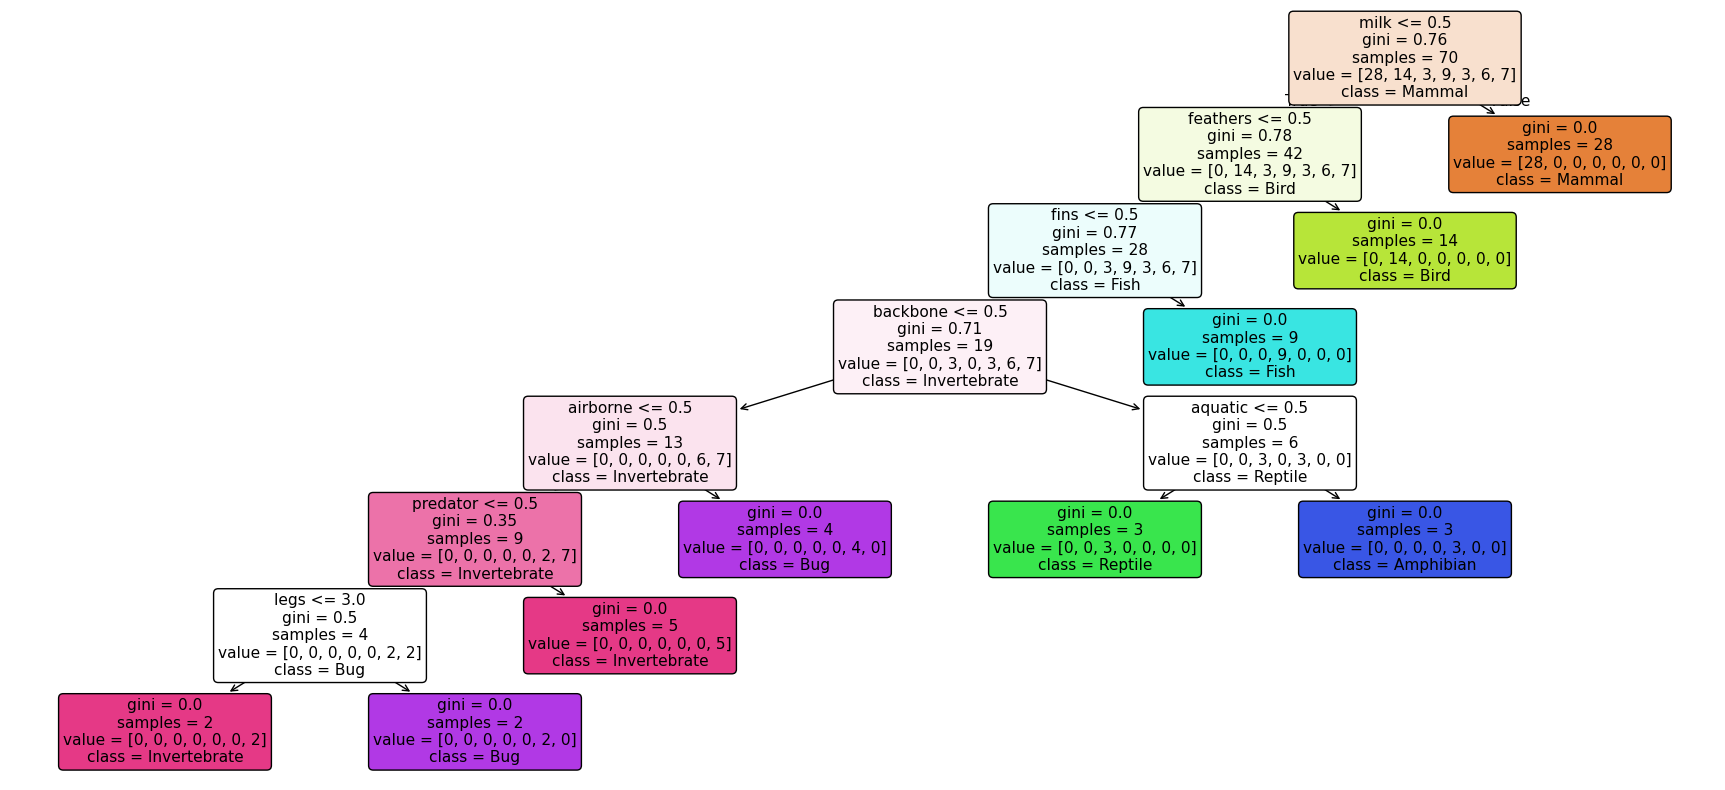

In [16]:
# Visualize the tree with sklearn's own plot_tree (no graphviz binary needed)
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 10))
plot_tree(model, filled=True, rounded=True,
          feature_names=feature_names,
          class_names=class_names,
          proportion=False, precision=2)
plt.show()


### Step 5. Measure the performance of the model

In [17]:
# Accuracy of the machine learning model

from sklearn.metrics import accuracy_score

acc = accuracy_score(Y_test, Y_predict)
print(acc * 100 , "%")

96.7741935483871 %


In [18]:
# Build the confusion matrix
# Confusion matrix is build from the actual test_targets to the predicted test_predict.

from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(Y_test, Y_predict)
print('Confusion Matrix :')
print(conf_matrix)

Confusion Matrix :
[[13  0  0  0  0  0  0]
 [ 0  6  0  0  0  0  0]
 [ 0  0  1  0  1  0  0]
 [ 0  0  0  4  0  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  0  0  0  2  0]
 [ 0  0  0  0  0  0  3]]


Exercise.

1. Identify another machine learning model from the sklearn library.
2. Apply the above steps to the identified model appropriately and measure its performance.
3. Compare the two models (model of this exercise and the identified model).